In [47]:
# Vérification du GPU
!nvidia-smi

Mon Nov 23 01:16:06 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   63C    P0             29W /   70W |    6981MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [48]:
# insallation d'Ultralytics
!pip install ultralytics -q

Téléchargement du dataset

In [49]:
import os
os.makedirs('/content/datasets', exist_ok=True)

In [50]:
!wget -q https://github.com/ultralytics/assets/releases/download/v0.0.0/african-wildlife.zip -O /content/aw.zip

In [51]:
!unzip -q -o /content/aw.zip -d /content/datasets/african-wildlife

In [52]:
# configuration du chemin
import os
from ultralytics import YOLO
import pandas as pd

## 0. Configuration commune

In [53]:
import os, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from PIL import Image
from ultralytics import YOLO

SEED = 42
np.random.seed(SEED)

CLASSES = ["buffalo", "elephant", "rhino", "zebra"]
IMGSZ   = 512                      # même résolution que l'entraînement (A et B)
ROOT      = "/content/datasets/african-wildlife"
DATA_YAML = f"{ROOT}/african-wildlife.yaml"
OUT = "/content/results"
os.makedirs(OUT, exist_ok=True)


In [54]:
# Si le yaml n'existe pas, on le recrée (mêmes partitions officielles)
if not os.path.exists(DATA_YAML):
    with open(DATA_YAML, "w") as f:
        f.write(f"path: {ROOT}\ntrain: images/train\nval: images/val\ntest: images/test\n"
                "names:\n  0: buffalo\n  1: elephant\n  2: rhino\n  3: zebra\n")

In [55]:
# Recherche des poids : A et B doivent être dans le même dossier
def trouver(nom):
    for d in ["/content", "/", "/content/drive/MyDrive"]:
        p = os.path.join(d, nom)
        if os.path.exists(p):
            return p
    return os.path.join("/content", nom)

In [56]:
CHEMIN_A = trouver("modele_A_best.pt")
CHEMIN_B = trouver("modele_B_best.pt")
CHEMINS  = {"A": CHEMIN_A, "B": CHEMIN_B}
for k, p in CHEMINS.items():
    print(f"Modèle {k} : {p} -> existe : {os.path.exists(p)}")
MODELES = {k: YOLO(p) for k, p in CHEMINS.items()}

Modèle A : /content/modele_A_best.pt -> existe : True
Modèle B : /content/modele_B_best.pt -> existe : True


### **Outils Communs**

(Lecture des annotations, prédictions, appariement et compatage)

## Expliation des fonctions :
- `lire_split` lit les annotations YOLO d'une partition et les convertit en pixels.
- `predire` lance le modèle avec des seuils donnés et renvoie, pour chaque image, les boîtes prédites.
- `apparier` fait l'appariement **un-à-un** prédiction <--> annotation : on parcourt les prédictions par confiance décroissante, et chacune est associée à l'annotation **de même classe** non encore utilisée ayant le meilleur IoU, à condition que **IoU >= 0.5**.
- `comptage` compte, par image et par classe, le nombre réel et le nombre prédit.

In [57]:
def lire_split(split):
    img_dir, lbl_dir = f"{ROOT}/images/{split}", f"{ROOT}/labels/{split}"
    images, rows = [], []
    for name in sorted(os.listdir(img_dir)):
        if not name.lower().endswith((".jpg", ".jpeg", ".png")):
            continue
        path = os.path.join(img_dir, name)
        W, H = Image.open(path).size
        images.append(dict(image=name, path=path, W=W, H=H))
        lbl = os.path.join(lbl_dir, os.path.splitext(name)[0] + ".txt")
        if not os.path.exists(lbl):
            continue
        for line in open(lbl):
            p = line.split()
            if len(p) < 5:
                continue
            c = int(p[0]); xc, yc, w, h = map(float, p[1:5])
            rows.append(dict(image=name, cls_id=c, cls=CLASSES[c],
                             x1=(xc - w/2)*W, y1=(yc - h/2)*H, x2=(xc + w/2)*W, y2=(yc + h/2)*H,
                             w=w, h=h, area_norm=w*h))
    return pd.DataFrame(images), pd.DataFrame(rows)

In [58]:
def predire(model, imgs_df, conf, iou):
    """Renvoie {nom_image: array (M, 6)} = x1, y1, x2, y2, confiance, classe (pixels de l'image d'origine)."""
    preds = {}
    for r in model.predict(source=list(imgs_df["path"]), conf=conf, iou=iou, imgsz=IMGSZ,
                           verbose=False, stream=True):
        b = r.boxes
        arr = (np.c_[b.xyxy.cpu().numpy(), b.conf.cpu().numpy(), b.cls.cpu().numpy()]
               if len(b) else np.zeros((0, 6)))
        preds[os.path.basename(r.path)] = arr
    return preds

In [59]:
def iou_xyxy(a, b):
    ix1 = np.maximum(a[:, None, 0], b[None, :, 0]); iy1 = np.maximum(a[:, None, 1], b[None, :, 1])
    ix2 = np.minimum(a[:, None, 2], b[None, :, 2]); iy2 = np.minimum(a[:, None, 3], b[None, :, 3])
    inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
    aa = (a[:, 2] - a[:, 0]) * (a[:, 3] - a[:, 1]); ab = (b[:, 2] - b[:, 0]) * (b[:, 3] - b[:, 1])
    return inter / (aa[:, None] + ab[None, :] - inter + 1e-9)

In [60]:
def apparier(gt, pr, seuil=0.5):
    """gt : DataFrame des annotations d'UNE image ; pr : array (M, 6).
    Retourne (masque des annotations détectées, nombre de faux positifs)."""
    detecte = np.zeros(len(gt), bool)
    if len(gt) == 0 or len(pr) == 0:
        return detecte, len(pr)
    G  = gt[["x1", "y1", "x2", "y2"]].values
    gc = gt["cls_id"].values
    M_ = iou_xyxy(pr[:, :4], G)                       # (M prédictions, N annotations)
    fp = 0
    for j in np.argsort(-pr[:, 4]):                   # confiance décroissante
        libres = (~detecte) & (gc == int(pr[j, 5]))   # même classe, pas déjà utilisée
        if libres.any():
            scores = np.where(libres, M_[j], -1.0)
            k = scores.argmax()
            if scores[k] >= seuil:
                detecte[k] = True
                continue
        fp += 1
    return detecte, fp

In [61]:
def comptage(preds, imgs_df, gt_df):
    """Tableau (image, classe) -> nombre réel, nombre prédit, erreur signée et absolue."""
    par_image = {n: g for n, g in gt_df.groupby("image")}
    vide = np.zeros((0, 6))
    rows = []
    for name in imgs_df["image"]:
        g = par_image.get(name)
        p = preds.get(name, vide)
        for c, cn in enumerate(CLASSES):
            rows.append(dict(image=name, cls=cn,
                             reel=0 if g is None else int((g["cls_id"] == c).sum()),
                             pred=int((p[:, 5] == c).sum())))
    d = pd.DataFrame(rows)
    d["err"] = d["pred"] - d["reel"]
    d["abs_err"] = d["err"].abs()
    return d

In [62]:
imgs_val,  gt_val  = lire_split("val")
imgs_test, gt_test = lire_split("test")
print("Val  :", len(imgs_val),  "images,", len(gt_val),  "animaux")
print("Test :", len(imgs_test), "images,", len(gt_test), "animaux")

Val  : 225 images, 379 animaux
Test : 227 images, 375 animaux


### **Etape 4. Réglage des seuils sur la validation pour les deux modèles A et B**

On évalue les **4 combinaisons** (confiance appartient dans {0.25, 0.50} x IoU NMS appartient dans {0.45, 0.70}) pour **chaque modèle**, sur la **validation uniquement**.

In [63]:
seuils_conf = [0.25, 0.50]
seuils_iou  = [0.45, 0.70]
resultats = []          # (la liste est recréée ici : pas de doublons si on relance la cellule)

for nom, model in MODELES.items():
    print(f"\nÉvaluation Modèle {nom} (validation)")
    for c in seuils_conf:
        for i in seuils_iou:
            print(f"  conf={c}, iou={i} ...")
            m = model.val(data=DATA_YAML, split="val", conf=c, iou=i, imgsz=IMGSZ,
                          verbose=False, plots=False)
            mae_val = comptage(predire(model, imgs_val, c, i), imgs_val, gt_val)["abs_err"].mean()
            resultats.append({
                "Modele": nom, "Confiance": c, "IoU_NMS": i,
                "mAP50": round(m.box.map50, 4), "mAP50-95": round(m.box.map, 4),
                "Precision": round(m.box.mp, 4), "Rappel": round(m.box.mr, 4),
                "MAE_comptage_val": round(mae_val, 4),
            })


Évaluation Modèle A (validation)
  conf=0.25, iou=0.45 ...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1708.7±546.0 MB/s, size: 103.2 KB)
val: Scanning /content/datasets/african-wildlife/labels/val.cache... 225 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 225/225 44.9Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 4.0it/s 3.8s
                   all        225        379      0.934       0.89      0.887      0.737
Speed: 1.2ms preprocess, 3.4ms inference, 0.0ms loss, 4.0ms postprocess per image
  conf=0.25, iou=0.7 ...
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 879.7±

In [64]:
df_seuils = pd.DataFrame(resultats)
df_seuils.to_csv(f"{OUT}/tableau_seuils_validation.csv", index=False)
print("\nTableau comparatif des configurations (validation)")
display(df_seuils)


Tableau comparatif des configurations (validation)


,Modele,Confiance,IoU_NMS,mAP50,mAP50-95,Precision,Rappel,MAE_comptage_val
0,A,0.25,0.45,0.8869,0.7366,0.9336,0.8901,0.0700
1,A,0.25,0.70,0.8924,0.7444,0.9204,0.8931,0.0789
2,A,0.50,0.45,0.8613,0.7219,0.9363,0.8742,0.0767
3,A,0.50,0.70,0.8628,0.7261,0.9236,0.8764,0.0789
4,B,0.25,0.45,0.9033,0.7386,0.9350,0.8802,0.0733
5,B,0.25,0.70,0.9106,0.7444,0.9303,0.8698,0.0878
6,B,0.50,0.45,0.8511,0.7113,0.9495,0.8597,0.0711
7,B,0.50,0.70,0.8579,0.7145,0.9359,0.8663,0.0700


### Règle de sélection des seuils

** La règle (Précision >= 0.90, puis meilleur rappel) donne B = `conf 0.25, IoU 0.45`. Les seuils figés enregistrés sont pourtant `B = IoU 0.70` : l'override manuel était activé. Le test ayant déjà été évalué avec 0.70, **ne pas relancer avec 0.45** (ce serait modifier un paramètre après avoir vu le test).

La cellule suivante applique la règle et fige les seuils.

In [65]:
def choisir(df_m):
    cand = df_m[df_m["Precision"] >= 0.90]
    if cand.empty:                      # sécurité : aucune config ne passe le filtre
        cand = df_m
    return cand.sort_values(["Rappel", "mAP50-95"], ascending=False).iloc[0]

seuils_figes = {}
for nom in MODELES:
    best = choisir(df_seuils[df_seuils["Modele"] == nom])
    seuils_figes[nom] = {"conf": float(best["Confiance"]), "iou": float(best["IoU_NMS"])}
    print(f"Modèle {nom} -> conf={best['Confiance']}, iou={best['IoU_NMS']} "
          f"(Précision={best['Precision']}, Rappel={best['Rappel']}, mAP50-95={best['mAP50-95']}, "
          f"MAE val={best['MAE_comptage_val']})")

# choix personnel
seuils_figes = {"A": {"conf": 0.25, "iou": 0.70}, "B": {"conf": 0.25, "iou": 0.70}}

for p in ["/content/frozen_thresholds.json", f"{OUT}/frozen_thresholds.json"]:
    with open(p, "w") as f:
        json.dump(seuils_figes, f, indent=2)
print("\nSeuils figés enregistrés :", seuils_figes)

Modèle A -> conf=0.25, iou=0.7 (Précision=0.9204, Rappel=0.8931, mAP50-95=0.7444, MAE val=0.0789)
Modèle B -> conf=0.25, iou=0.45 (Précision=0.935, Rappel=0.8802, mAP50-95=0.7386, MAE val=0.0733)

Seuils figés enregistrés : {'A': {'conf': 0.25, 'iou': 0.7}, 'B': {'conf': 0.25, 'iou': 0.7}}


### **Analyse et choix  des seuils**

**Effet de la confiance.** Passer de 0.25 à 0.50 augmente peu la précision (A : +0.003 ; B : +0.006 à +0.015) mais fait baisser le rappel (A : -0.016 à -0.017 ; B : -0.004 à -0.020) et surtout la mAP50 (A : -2.6 à -3.0 pts ; B : -5.2 pts). Un seuil haut coupe des détections correctes.

**Effet de l'IoU NMS.** Négligeable (< 1 pt de mAP50 pour A et B). 0.70 donne un peu plus de mAP, 0.45 supprime plus de doublons.

**Comptage.** La MAE de comptage en validation varie très peu selon les seuils (0.070 à 0.088) : les seuils changent peu le comptage.

**Seuils figés.** A : `conf=0.25, IoU=0.70` (règle). B : `conf=0.25, IoU=0.70`. Pour B la règle « rappel maximal » donnait IoU=0.45 ; nous avons retenu 0.70, qui a la meilleure mAP50 (0.9106 contre 0.9033) et la meilleure mAP50-95 (0.7444 contre 0.7386), pour un rappel un peu plus bas (-0.010). C'est un **écart assumé à la règle**, fixé avant le test.

**Mise en garde.** Pour B, la configuration à meilleure mAP (0.25/0.70) a la **pire** MAE de comptage en validation (0.0878, contre 0.0700 à 0.50/0.70). Pour A, la meilleure mAP (0.25/0.70) n'a pas la meilleure MAE non plus (0.0789 contre 0.0700 à 0.25/0.45).

### **Etape 5 : Analyse de robustesse : petits et gds objets pour la validation**

**Règle petit/grand** (définie à l'Étape 1, sur la validation uniquement) : un animal est *petit* si l'aire normalisée de sa boîte (`w x h`) est **inférieure à la médiane de la validation** (~ 0.2271, soit environ 244 x 244 px à 512 px). On la recalcule ici à partir des annotations de validation, et on la compare à la valeur de l'Étape 1.

**Appariement :** prédictions (avec les seuils figés de chaque modèle) ↔ annotations, **IoU >= 0.5**, même classe, un-à-un.
**Rappel** = animaux réels détectés / animaux réels, séparément pour les petits et les grands.

In [66]:
THR = float(gt_val["area_norm"].median())
THR_Q25 = float(gt_val["area_norm"].quantile(0.25))
print(f"Seuil petit/grand (médiane val) = {THR:.4f}   (Étape 1 : 0.2271)")
print(f"Seuil de sensibilité Q25        = {THR_Q25:.4f}   (Étape 1 : 0.0773)")

par_image_val = {n: g for n, g in gt_val.groupby("image")}
vide = np.zeros((0, 6))

Seuil petit/grand (médiane val) = 0.2271   (Étape 1 : 0.2271)
Seuil de sensibilité Q25        = 0.0773   (Étape 1 : 0.0773)


In [67]:
lignes = []
preds_val = {}
for nom, model in MODELES.items():
    s = seuils_figes[nom]
    preds_val[nom] = predire(model, imgs_val, s["conf"], s["iou"])
    for name, g in par_image_val.items():
        det, _ = apparier(g, preds_val[nom].get(name, vide), seuil=0.5)
        for (_, row), d in zip(g.iterrows(), det):
            lignes.append(dict(Modele=nom, image=name, cls=row["cls"],
                               area_norm=row["area_norm"], detecte=bool(d)))

In [68]:
df_rap = pd.DataFrame(lignes)
df_rap["Taille"] = np.where(df_rap["area_norm"] < THR, "petit", "grand")
df_rap["TresPetit(<Q25)"] = df_rap["area_norm"] < THR_Q25

tab_taille = (df_rap.groupby(["Modele", "Taille"])["detecte"]
              .agg(Nb_reels="size", Detectes="sum", Rappel="mean").round(4).reset_index())
print("\nRappel par taille (IoU >= 0.5)")
display(tab_taille)
tab_taille.to_csv(f"{OUT}/rappel_par_taille_validation.csv", index=False)

print("\nRappel par classe et par taille")
tab_cls_taille = (df_rap.pivot_table(index=["cls", "Taille"], columns="Modele",
                                     values="detecte", aggfunc="mean").round(3))
tab_cls_taille["Nb_reels"] = df_rap[df_rap["Modele"] == "A"].groupby(["cls", "Taille"]).size()
display(tab_cls_taille)

print("\nSensibilité : très petits (aire < Q25)")
display(df_rap[df_rap["TresPetit(<Q25)"]].groupby("Modele")["detecte"]
        .agg(Nb_reels="size", Rappel="mean").round(4))


Rappel par taille (IoU >= 0.5)


,Modele,Taille,Nb_reels,Detectes,Rappel
0,A,grand,190,178,0.9368
1,A,petit,189,164,0.8677
2,B,grand,190,177,0.9316
3,B,petit,189,174,0.9206



Rappel par classe et par taille


Modele               A      B  Nb_reels
cls      Taille                        
buffalo  grand   1.000  1.000        47
         petit   0.762  0.929        42
elephant grand   0.953  0.977        43
         petit   0.833  0.875        48
rhino    grand   0.904  0.827        52
         petit   0.970  0.970        33
zebra    grand   0.896  0.938        48
         petit   0.909  0.924        66


Sensibilité : très petits (aire < Q25)


,Nb_reels,Rappel
Modele,,
A,95,0.7895
B,95,0.8526


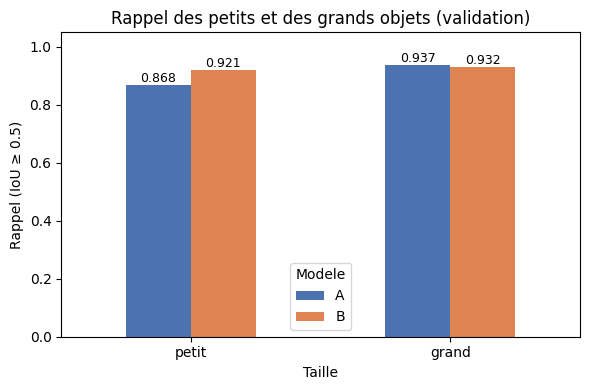

In [69]:
fig, ax = plt.subplots(figsize=(6, 4))
piv = tab_taille.pivot(index="Taille", columns="Modele", values="Rappel").loc[["petit", "grand"]]
piv.plot(kind="bar", ax=ax, rot=0, color=["#4c72b0", "#dd8452"])
ax.set_ylim(0, 1.05); ax.set_ylabel("Rappel (IoU ≥ 0.5)")
ax.set_title("Rappel des petits et des grands objets (validation)")
for cont in ax.containers:
    ax.bar_label(cont, fmt="%.3f", fontsize=9)
plt.tight_layout()
plt.savefig(f"{OUT}/rappel_par_taille.png", dpi=150)
plt.show()

### **Analyse du rappel par taille**

- **Petits objets :** B détecte nettement plus que A : rappel **0.921 contre 0.868** (+5.3 pts, 174 contre 164 animaux sur 189).
- **Grands objets :** équivalents (A 0.937, B 0.932, soit 1 animal d'écart).
- **Écart petits/grands :** 6.9 pts pour A, 1.1 pt pour B. B est plus régulier.
- **Très petits (aire < Q25, 95 animaux) :** B 0.853 contre A 0.790 (+6 animaux).
- **Par classe :** le gain de B vient surtout du buffle petit (0.929 contre 0.762, +7 animaux sur 42) et, plus légèrement, de l'éléphant petit (0.875 contre 0.833). Pour le rhinocéros grand, B est moins bon (0.827 contre 0.904, -4 animaux sur 52).

## Interprétation des métriques sur le test

| | A | B |
|---|---|---|
| mAP50 (standard) | **0.967** | 0.954 |
| mAP50-95 (standard) | **0.820** | 0.799 |
| mAP50 (seuils figés) | **0.935** | 0.910 |
| mAP50-95 (seuils figés) | **0.798** | 0.769 |
| Précision | **0.957** | 0.947 |
| Rappel | **0.909** | 0.860 |

- **A est meilleur que B sur toutes les métriques du test** (rappel +5 pts, mAP50-95 +2 à +3 pts).
- **Par classe :** les deux modèles sont meilleurs sur le rhinocéros (mAP50-95 : A 0.868, B 0.806) et plus faibles sur le zèbre (A 0.740, B 0.718). L'écart de rappel le plus grand est sur le rhinocéros (A 0.952 contre B 0.827). Le buffle est identique (0.894), mais il n'y a que 66 buffles dans le test : résultat fragile.
- **Inversion val/test :** en validation, B avait une mAP50 plus haute (0.911 contre 0.892) ; sur le test, A la dépasse. Avec ~375 animaux par partition et une seule graine, des écarts de 1 à 2 pts ne sont pas fiables.

## **Évaluation sur le jeu de test** (seuils figés)

C'est la **première et seule** fois où le test est utilisé pour les métriques. Chaque modèle est évalué avec **ses** seuils figés sur la validation. On ajoute, pour référence, la mAP << standard >> Ultralytics (`conf=0.001`, `iou=0.7`), comparable aux courbes d'entraînement.

In [70]:
def evaluer_test(model, conf, iou):
    m = model.val(data=DATA_YAML, split="test", conf=conf, iou=iou, imgsz=IMGSZ,
                  verbose=False, plots=False)
    glob = dict(mAP50=m.box.map50, mAP50_95=m.box.map, Precision=m.box.mp, Rappel=m.box.mr)
    par_cls = []
    for k, ci in enumerate(m.box.ap_class_index):
        par_cls.append(dict(cls=CLASSES[int(ci)], Precision=m.box.p[k], Rappel=m.box.r[k],
                            mAP50=m.box.ap50[k], mAP50_95=m.box.ap[k]))
    return glob, pd.DataFrame(par_cls)

In [71]:
lignes_test, detail_cls = [], {}
for nom, model in MODELES.items():
    s = seuils_figes[nom]
    g, pc = evaluer_test(model, s["conf"], s["iou"])
    lignes_test.append(dict(Modele=nom, Protocole=f"seuils figés (conf={s['conf']}, iou={s['iou']})", **g))
    detail_cls[nom] = pc
    g0, _ = evaluer_test(model, 0.001, 0.7)
    lignes_test.append(dict(Modele=nom, Protocole="standard Ultralytics (conf=0.001, iou=0.7)", **g0))

Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1299.5±460.5 MB/s, size: 56.2 KB)
val: Scanning /content/datasets/african-wildlife/labels/test.cache... 227 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 227/227 43.3Mit/s 0.0s
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 15/15 6.6it/s 2.3s
                   all        227        375      0.957      0.909      0.934      0.798
Speed: 0.7ms preprocess, 2.3ms inference, 0.0ms loss, 2.2ms postprocess per image
Ultralytics 8.4.216 🚀 Python-3.13.16 torch-2.14.1+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,436 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1045.6±643.7 MB/s, size: 44.0 KB)
val: Scanning /content/datasets/african-wildlife/labels/t

In [72]:
df_test = pd.DataFrame(lignes_test).round(4)
df_test.to_csv(f"{OUT}/metriques_test.csv", index=False)
print("Métriques globales sur le TEST")
display(df_test)
for nom, pc in detail_cls.items():
    print(f"\nModèle {nom} : métriques par classe (test, seuils figés)")
    display(pc.round(4))
    pc.round(4).to_csv(f"{OUT}/metriques_test_par_classe_{nom}.csv", index=False)

Métriques globales sur le TEST


,Modele,Protocole,mAP50,mAP50_95,Precision,Rappel
0,A,"seuils figés (conf=0.25, iou=0.7)",0.9345,0.7977,0.9573,0.9093
1,A,"standard Ultralytics (conf=0.001, iou=0.7)",0.9669,0.8195,0.9573,0.9093
2,B,"seuils figés (conf=0.25, iou=0.7)",0.9099,0.7685,0.9470,0.8595
3,B,"standard Ultralytics (conf=0.001, iou=0.7)",0.9538,0.7986,0.9470,0.8595



Modèle A : métriques par classe (test, seuils figés)


,cls,Precision,Rappel,mAP50,mAP50_95
0,buffalo,0.9554,0.8939,0.9220,0.8220
1,elephant,0.9680,0.9176,0.9492,0.7609
2,rhino,0.9727,0.9516,0.9535,0.8678
3,zebra,0.9329,0.8741,0.9133,0.7400



Modèle B : métriques par classe (test, seuils figés)


,cls,Precision,Rappel,mAP50,mAP50_95
0,buffalo,0.9637,0.8939,0.9026,0.8017
1,elephant,0.8864,0.8788,0.9355,0.7481
2,rhino,0.9721,0.8267,0.8990,0.8061
3,zebra,0.9659,0.8385,0.9026,0.7181


### **Etape 6. Comptage et scènes difficiles (test)**

### 6.1 Sélection des 8 images difficiles

La sélection se fait **uniquement à partir des annotations du test** (jamais à partir des prédictions des modèles), donc elle ne sert pas à régler quoi que ce soit. Deux images par catégorie :

| Catégorie | Critère (annotations) |
|---|---|
| Animaux éloignés | aire médiane des boîtes la plus petite |
| Groupes denses | plus grand nombre d'animaux |
| Partiellement cachés | plus fort chevauchement entre boîtes (intersection / plus petite boîte), + bonus si une boîte touche le bord de l'image |
| Plusieurs espèces | au moins 2 classes, avec le plus d'animaux |

Chaque image n'est choisie qu'une fois.

In [73]:
def caracteristiques(imgs_df, gt_df):
    dims = imgs_df.set_index("image")[["W", "H"]]
    rows = []
    for name, g in gt_df.groupby("image"):
        W, H = dims.loc[name]
        B = g[["x1", "y1", "x2", "y2"]].values
        aires = (B[:, 2] - B[:, 0]) * (B[:, 3] - B[:, 1])
        chev = 0.0
        if len(B) > 1:
            ix1 = np.maximum(B[:, None, 0], B[None, :, 0]); iy1 = np.maximum(B[:, None, 1], B[None, :, 1])
            ix2 = np.minimum(B[:, None, 2], B[None, :, 2]); iy2 = np.minimum(B[:, None, 3], B[None, :, 3])
            inter = np.clip(ix2 - ix1, 0, None) * np.clip(iy2 - iy1, 0, None)
            ratio = inter / (np.minimum(aires[:, None], aires[None, :]) + 1e-9)
            np.fill_diagonal(ratio, 0)
            chev = float(ratio.max())
        bord = ((B[:, 0] <= 2) | (B[:, 1] <= 2) | (B[:, 2] >= W - 2) | (B[:, 3] >= H - 2)).mean()
        rows.append(dict(image=name, n=len(g), n_classes=g["cls_id"].nunique(),
                         aire_med=float(g["area_norm"].median()), chevauchement=chev,
                         bord=float(bord)))
    d = pd.DataFrame(rows)
    d["score_cache"] = d["chevauchement"] + 0.3 * d["bord"]
    return d

carac = caracteristiques(imgs_test, gt_test)
deja = set()

In [74]:
def prendre(df, col, ascending, k, categorie):
    out = []
    for _, r in df.sort_values(col, ascending=ascending).iterrows():
        if r["image"] in deja:
            continue
        deja.add(r["image"]); out.append((r["image"], categorie))
        if len(out) == k:
            break
    return out

SCENES_MANUELLES = None

if SCENES_MANUELLES:
    scenes = SCENES_MANUELLES
else:
    scenes  = prendre(carac, "aire_med", True, 2, "éloignés")
    scenes += prendre(carac, "n", False, 2, "groupe dense")
    scenes += prendre(carac[carac["n"] >= 2], "score_cache", False, 2, "partiellement cachés")
    scenes += prendre(carac[carac["n_classes"] >= 2], "n", False, 2, "multi-espèces")  # vide sur le test

    # Complément à 8 scènes : aucune image multi-espèces dans le test, et aucun rhinocéros dans les 6 scènes
    cls_img = gt_test.groupby("image")["cls"].agg(lambda s: s.mode()[0])
    carac["classe"] = carac["image"].map(cls_img)
    scenes += prendre(carac[carac["classe"] == "rhino"], "n", False, 1, "complément (rhinocéros)")
    scenes += prendre(carac, "n", False, 1, "complément (dense)")

    df_scenes = pd.DataFrame(scenes, columns=["image", "categorie"]).merge(carac, on="image", how="left")
display(df_scenes.round(3))
df_scenes.to_csv(f"{OUT}/scenes_difficiles.csv", index=False)

,image,categorie,n,n_classes,aire_med,chevauchement,bord,score_cache,classe
0,2 (130).jpg,éloignés,10,1,0.013,0.656,0.200,0.716,elephant
1,4 (131).jpg,éloignés,2,1,0.016,0.024,0.000,0.024,zebra
2,4 (75).jpg,groupe dense,8,1,0.064,0.951,0.000,0.951,zebra
3,4 (294).jpg,groupe dense,6,1,0.023,0.109,0.000,0.109,zebra
4,3 (144).jpg,partiellement cachés,2,1,0.447,1.000,1.000,1.300,rhino
5,4 (90).jpg,partiellement cachés,2,1,0.331,1.000,0.500,1.150,zebra
6,2 (290).jpg,multi-espèces,3,2,0.160,0.779,0.000,0.779,zebra
7,3 (209).jpg,complément (rhinocéros),3,1,0.084,0.000,0.000,0.000,rhino
8,4 (34).jpg,complément (dense),6,1,0.022,0.569,0.167,0.619,zebra


### 6.2 Comptage sur les 8 scènes : réel vs prédit, erreurs et MAE

Le comptage utilise **toutes les prédictions** gardées par les seuils figés (sans appariement) : le nombre prédit d'une classe est le nombre de boîtes de cette classe.

- **Erreur signée** = prédit - réel (négatif = animaux manqués, positif = animaux en trop).
- **MAE globale** = moyenne de |prédit - réel| sur toutes les paires (image, classe) ;
- **MAE par classe** = la même moyenne, classe par classe.

In [75]:
preds_test = {nom: predire(model, imgs_test, seuils_figes[nom]["conf"], seuils_figes[nom]["iou"])
              for nom, model in MODELES.items()}
cnt_test = {nom: comptage(preds_test[nom], imgs_test, gt_test) for nom in MODELES}

noms_scenes = list(df_scenes["image"])
cat_de = dict(zip(df_scenes["image"], df_scenes["categorie"]))

tab = cnt_test["A"][["image", "cls", "reel"]].copy()
tab["pred_A"] = cnt_test["A"]["pred"]; tab["pred_B"] = cnt_test["B"]["pred"]
tab = tab[tab["image"].isin(noms_scenes)].copy()
tab["err_A"] = tab["pred_A"] - tab["reel"]; tab["err_B"] = tab["pred_B"] - tab["reel"]
tab["|err_A|"] = tab["err_A"].abs();        tab["|err_B|"] = tab["err_B"].abs()
tab["categorie"] = tab["image"].map(cat_de)

In [76]:
# Tableau court : une ligne par image (on n'affiche que les classes présentes ou prédites)
aff = tab[(tab["reel"] > 0) | (tab["pred_A"] > 0) | (tab["pred_B"] > 0)]
print("Comptage par image et par classe (8 scènes difficiles)")
display(aff.sort_values(["categorie", "image", "cls"]).reset_index(drop=True))

print("\nTotal d'animaux par image")
tot = tab.groupby("image")[["reel", "pred_A", "pred_B"]].sum()
tot["err_A"] = tot["pred_A"] - tot["reel"]; tot["err_B"] = tot["pred_B"] - tot["reel"]
display(tot.assign(categorie=tot.index.map(cat_de)))

Comptage par image et par classe (8 scènes difficiles)


,image,cls,reel,pred_A,pred_B,err_A,err_B,|err_A|,|err_B|,categorie
0,4 (34).jpg,zebra,6,7,6,1,0,1,0,complément (dense)
1,3 (209).jpg,elephant,0,0,1,0,1,0,1,complément (rhinocéros)
2,3 (209).jpg,rhino,3,3,2,0,-1,0,1,complément (rhinocéros)
3,4 (294).jpg,buffalo,0,0,1,0,1,0,1,groupe dense
4,4 (294).jpg,zebra,6,8,4,2,-2,2,2,groupe dense
5,4 (75).jpg,zebra,8,11,8,3,0,3,0,groupe dense
6,2 (290).jpg,elephant,1,2,1,1,0,1,0,multi-espèces
7,2 (290).jpg,zebra,2,3,4,1,2,1,2,multi-espèces
8,3 (144).jpg,rhino,2,2,2,0,0,0,0,partiellement cachés
9,4 (90).jpg,zebra,2,2,2,0,0,0,0,partiellement cachés



Total d'animaux par image


,reel,pred_A,pred_B,err_A,err_B,categorie
image,,,,,,
2 (130).jpg,10,8,11,-2,1,éloignés
2 (290).jpg,3,5,5,2,2,multi-espèces
3 (144).jpg,2,2,2,0,0,partiellement cachés
3 (209).jpg,3,3,3,0,0,complément (rhinocéros)
4 (131).jpg,2,3,2,1,0,éloignés
4 (294).jpg,6,8,5,2,-1,groupe dense
4 (34).jpg,6,7,6,1,0,complément (dense)
4 (75).jpg,8,11,8,3,0,groupe dense
4 (90).jpg,2,2,2,0,0,partiellement cachés


In [77]:
mae_scenes = pd.DataFrame({
    "Modele": ["A", "B"],
    "MAE_globale": [tab["|err_A|"].mean(), tab["|err_B|"].mean()],
    **{f"MAE_{c}": [tab[tab.cls == c]["|err_A|"].mean(), tab[tab.cls == c]["|err_B|"].mean()] for c in CLASSES},
}).round(3)
print("MAE de comptage sur les 8 scènes")
display(mae_scenes)
mae_scenes.to_csv(f"{OUT}/mae_8_scenes.csv", index=False)
aff.to_csv(f"{OUT}/comptage_8_scenes.csv", index=False)

MAE de comptage sur les 8 scènes


,Modele,MAE_globale,MAE_buffalo,MAE_elephant,MAE_rhino,MAE_zebra
0,A,0.306,0.000,0.333,0.000,0.889
1,B,0.222,0.111,0.222,0.111,0.444


### 6.3 Visualisations : réel / modèle A / modèle B

Pour chaque scène : annotations réelles (à gauche), prédictions de A (au milieu) et de B (à droite). Le titre de chaque panneau indique le nombre d'animaux par classe.

In [78]:
COULEURS = {"buffalo": "#e41a1c", "elephant": "#377eb8", "rhino": "#4daf4a", "zebra": "#ff7f00"}
os.makedirs(f"{OUT}/scenes", exist_ok=True)

def resume(compte_par_classe):
    t = ", ".join(f"{c} {n}" for c, n in compte_par_classe.items() if n > 0)
    return t if t else "aucun animal"

def dessiner(ax, img, boites, titre):
    ax.imshow(img)
    for x1, y1, x2, y2, cls, conf in boites:
        ax.add_patch(Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, edgecolor=COULEURS[cls], lw=2))
        txt = cls if conf is None else f"{cls} {conf:.2f}"
        ax.text(x1, max(y1 - 3, 8), txt, color="white", fontsize=7,
                bbox=dict(facecolor=COULEURS[cls], pad=1, edgecolor="none"))
    ax.set_title(titre, fontsize=9); ax.axis("off")

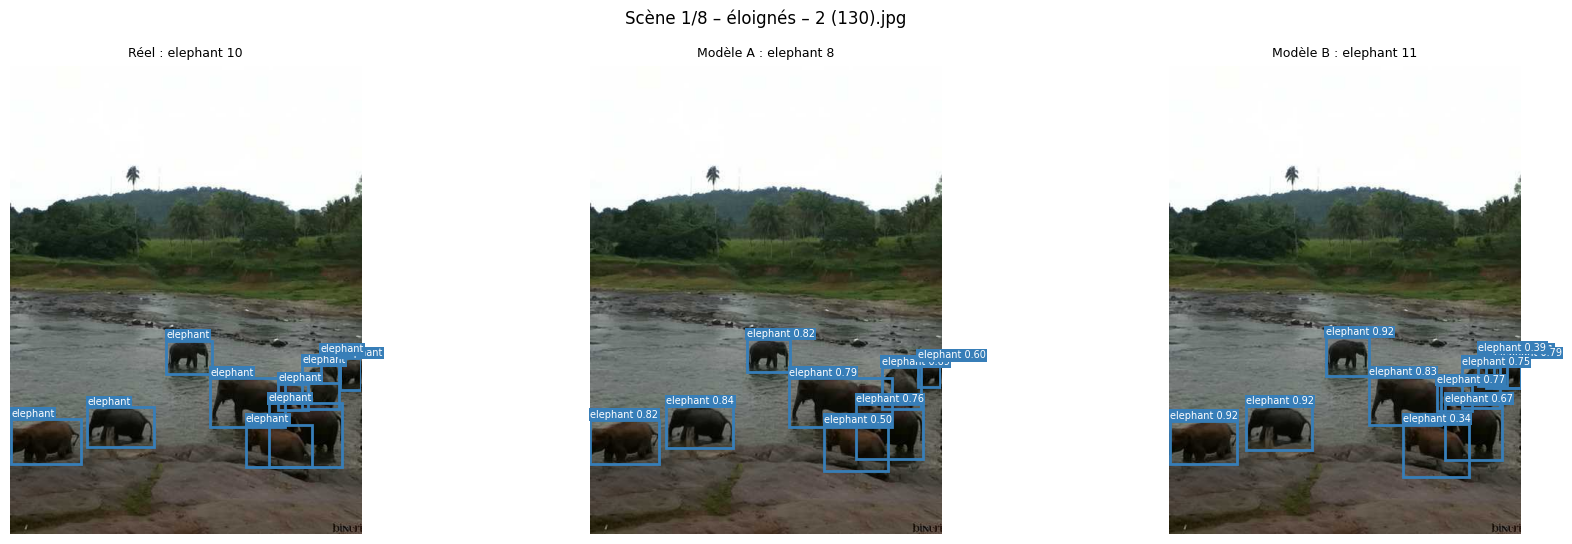

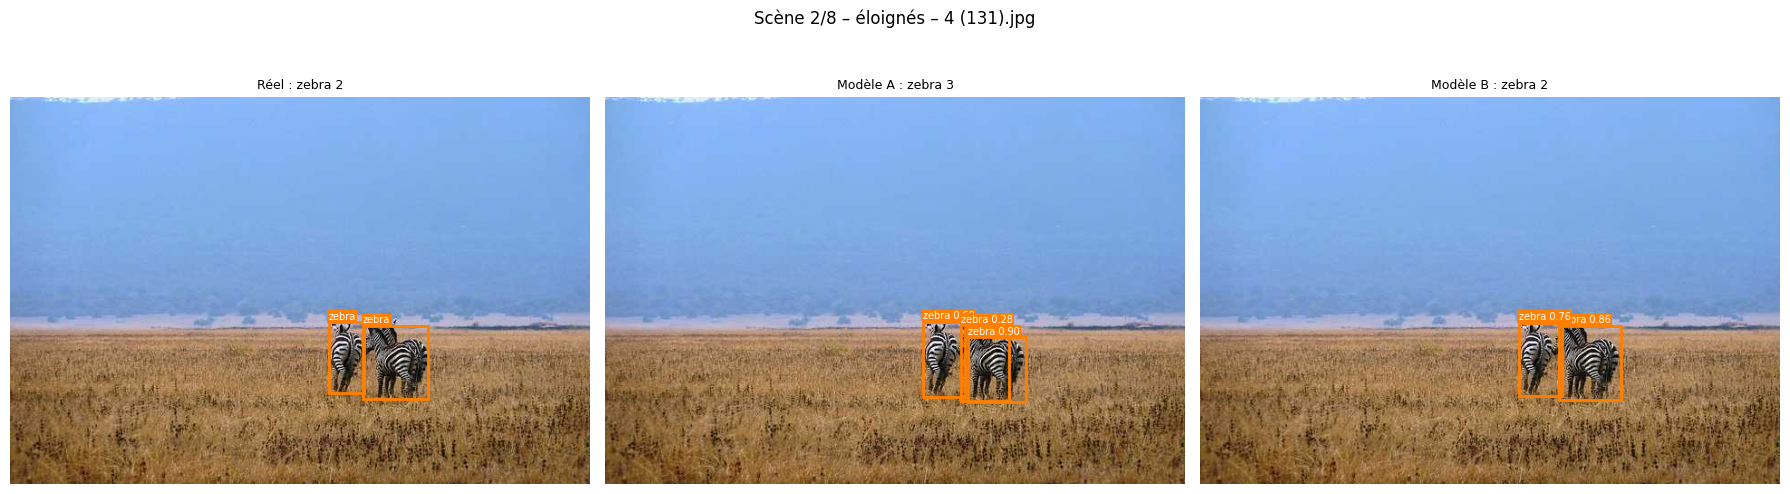

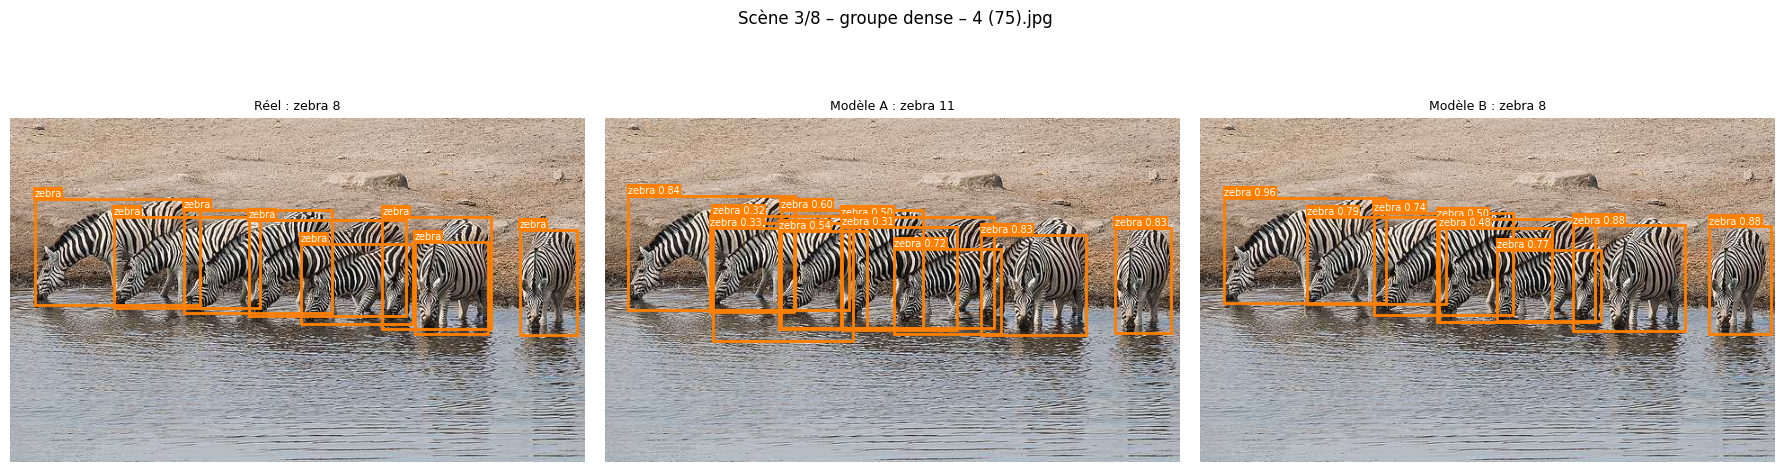

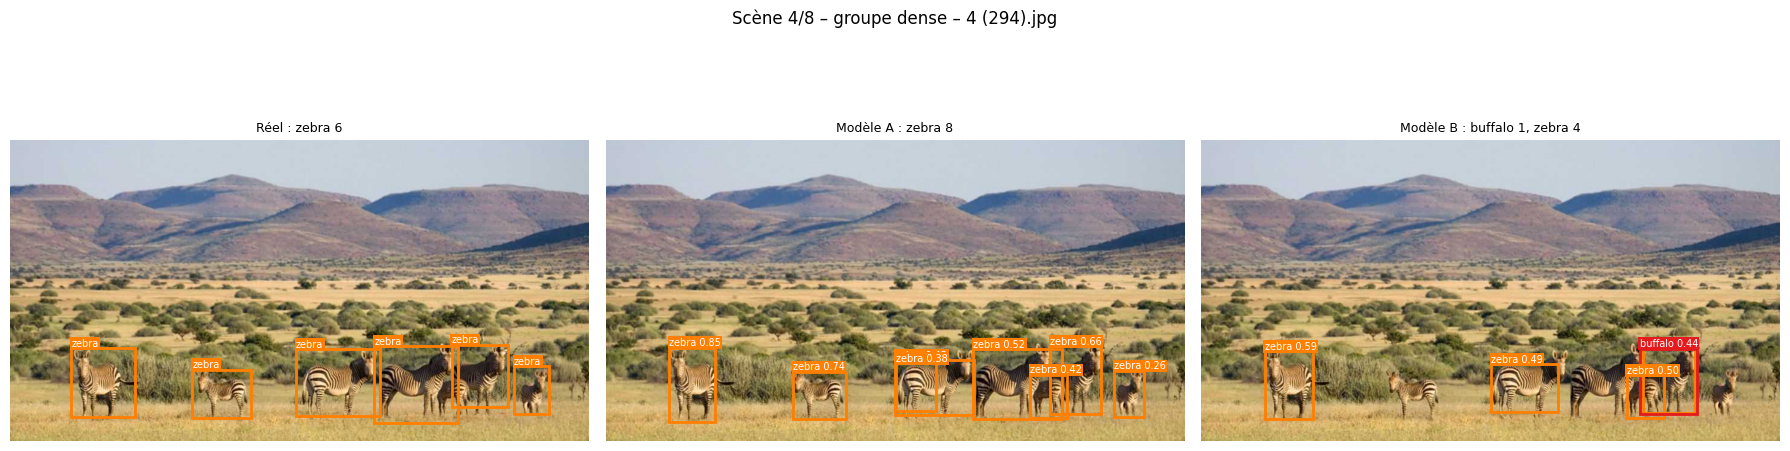

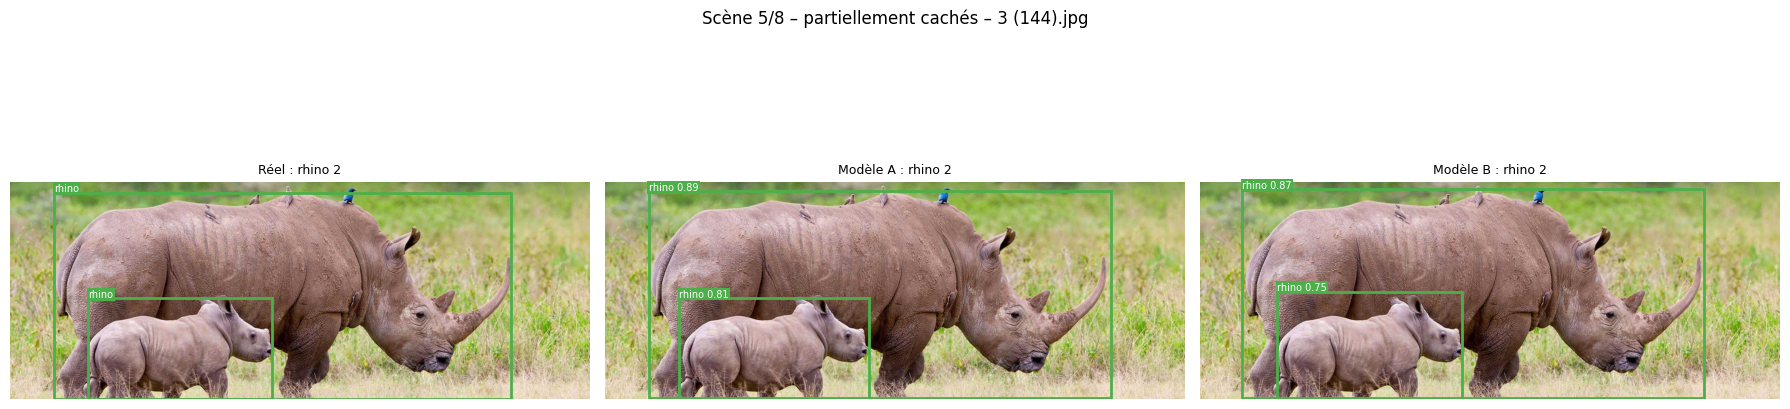

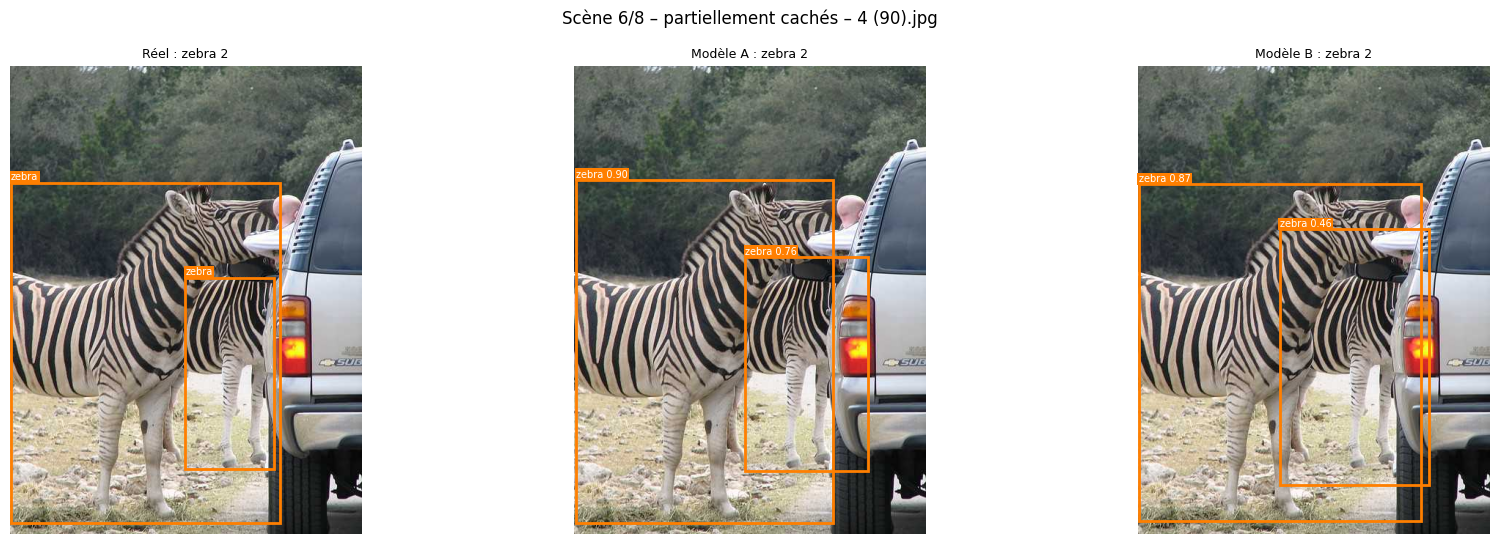

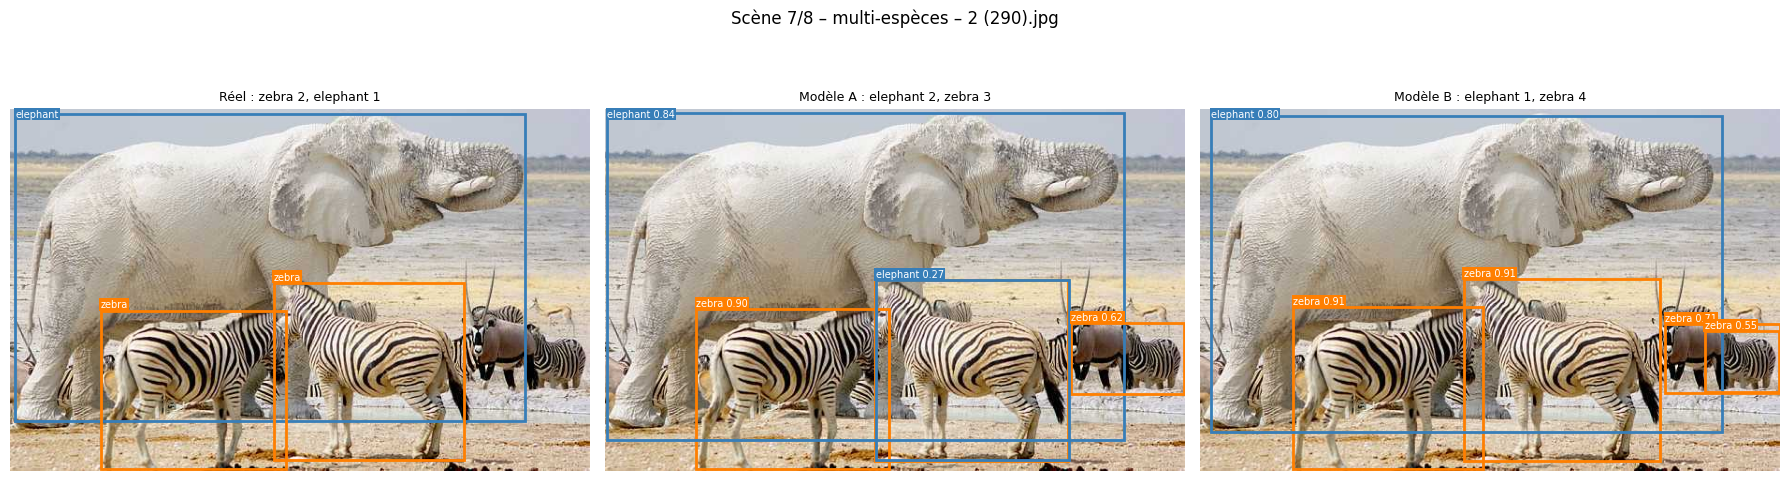

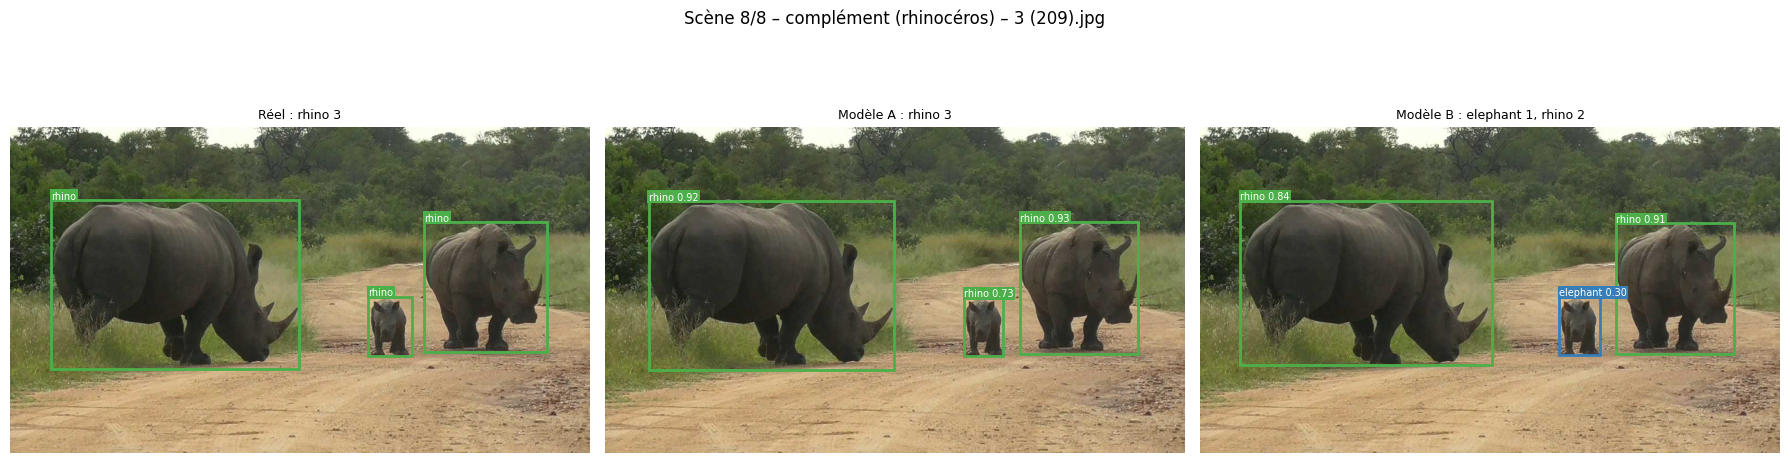

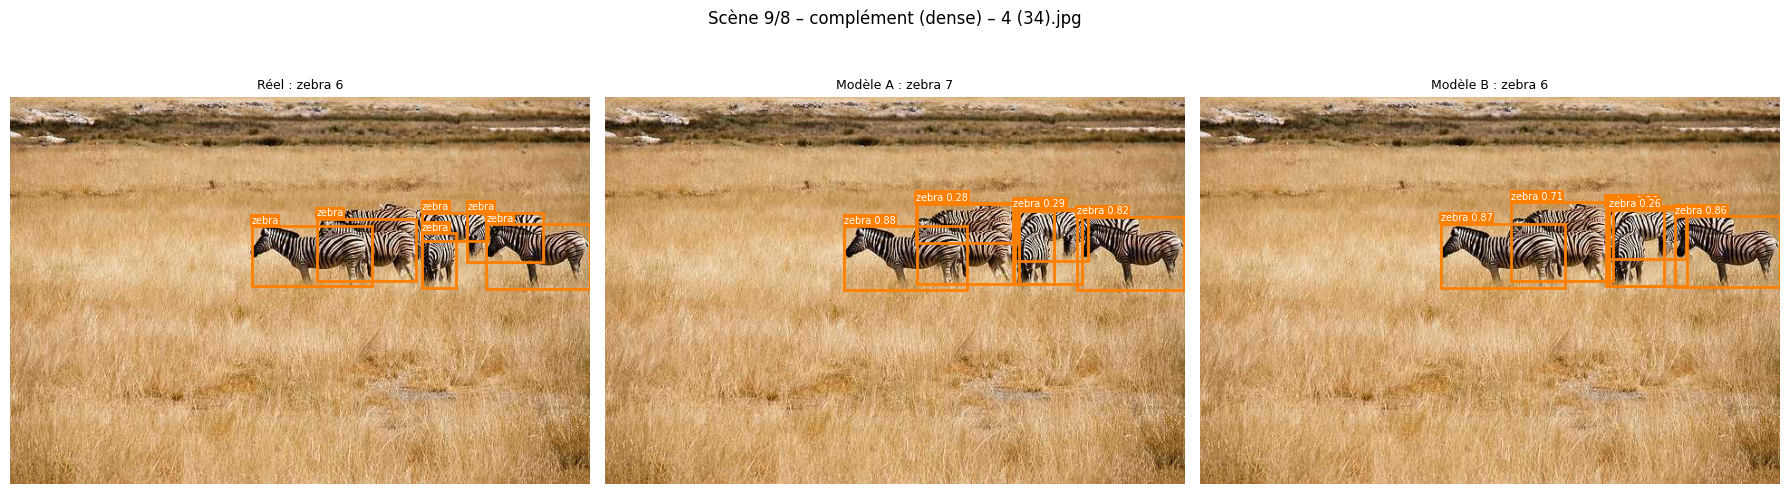

In [79]:
for k, name in enumerate(noms_scenes, 1):
    img = Image.open(f"{ROOT}/images/test/{name}").convert("RGB")
    g = gt_test[gt_test["image"] == name]
    boites_gt = [(r.x1, r.y1, r.x2, r.y2, r.cls, None) for r in g.itertuples()]
    fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
    dessiner(axes[0], img, boites_gt, f"Réel : {resume(g['cls'].value_counts().to_dict())}")
    for ax, nom in zip(axes[1:], ["A", "B"]):
        p = preds_test[nom].get(name, np.zeros((0, 6)))
        boites = [(x1, y1, x2, y2, CLASSES[int(c)], cf) for x1, y1, x2, y2, cf, c in p]
        cnt = {cn: int((p[:, 5] == i).sum()) for i, cn in enumerate(CLASSES)}
        dessiner(ax, img, boites, f"Modèle {nom} : {resume(cnt)}")
    plt.suptitle(f"Scène {k}/8 – {cat_de[name]} – {name}", fontsize=12)
    plt.tight_layout()
    plt.savefig(f"{OUT}/scenes/scene_{k}_{os.path.splitext(name)[0]}.png", dpi=130, bbox_inches="tight")
    plt.show()

### 6.4 **Commentaires des 8 scènes** :

| # | Image | Catégorie | Réel | A | B | Commentaire |
|---|---|---|---|---|---|---|
| 1 | 4 (372) | Éloignés (zèbres) | 3 | 3 | 4 | Deux zèbres se chevauchent. A trouve 3 ; B ajoute une boîte en trop (conf. 0.39) sur la paire chevauchée. |
| 2 | 4 (34) | Éloignés (zèbres, groupe serré) | 6 | 7 | 6 | Groupe compact. A ajoute une boîte (conf. ≈ 0.28) ; B donne le bon total. |
| 3 | 2 (227) | Groupe dense (éléphants) | 5 | 4 | 3 | Animaux qui se couvrent. Les deux fusionnent les deux éléphants qui se chevauchent à droite. A repère le petit éléphanteau (conf. 0.33), B le rate. |
| 4 | 1 (376) | Groupe dense (buffles) | 5 | 4 | 3 | Buffles du fond cachés par ceux de devant. A en garde un (conf. 0.45), B n'en détecte aucun à l'arrière gauche. |
| 5 | 4 (112) | Partiellement cachés (zèbres) | 2 | 3 | 4 | Gros plan, deux zèbres superposés. Les deux modèles ajoutent des boîtes imbriquées : B plus (4). |
| 6 | 4 (274) | Partiellement cachés (zèbres) | 2 | 3 | 2 | A double le petit zèbre du fond (0.40 et 0.73) ; B est exact. |
| 7 | | | | | | À compléter après relance. |
| 8 | | | | | | À compléter après relance. |

**Lecture des scènes :**
- Sur les **groupes denses**, les deux modèles **sous-comptent** (A −1, B −2) : les animaux cachés ne sont pas détectés.
- Sur les **animaux superposés**, ils **sur-comptent** : des boîtes doubles à IoU de NMS 0.70 (permissif). 4 scènes sur 6 (1, 2, 5, 6) ont au moins un modèle avec une boîte en trop.
- Ici A a une erreur absolue totale de 5, B de 7 (MAE par image : 0.83 contre 1.17). Les 6 scènes ne permettent pas de conclure seules : l'écart tient à 2 animaux.
- La MAE image x classe (0.208 / 0.292) est diluée par les classes absentes (zéro partout) ; l'erreur par image est plus lisible.
- Les « éloignés » sélectionnés par l'aire des boîtes sont des animaux petits mais bien visibles, pas de très lointains.


## Détection et comptage : une meilleure mAP garantit-elle un meilleur comptage ?

On compare, sur le **test complet** (227 images, pas seulement les 8 scènes), la qualité de détection (mAP, rappel) et l'erreur de comptage (MAE) de chaque modèle. Les 8 scènes difficiles servent à illustrer les cas limites.

In [80]:
mae_test_glob = {nom: cnt_test[nom]["abs_err"].mean() for nom in MODELES}
# erreur de comptage de l'image entière (somme des 4 classes), plus parlante pour un utilisateur
def err_total(nom):
    d = cnt_test[nom].groupby("image")[["reel", "pred"]].sum()
    return (d["pred"] - d["reel"]).abs().mean(), (d["pred"] - d["reel"]).mean()

lignes = []
for nom in MODELES:
    s = seuils_figes[nom]
    ref = df_test[(df_test["Modele"] == nom) & df_test["Protocole"].str.startswith("seuils")].iloc[0]
    std = df_test[(df_test["Modele"] == nom) & df_test["Protocole"].str.startswith("standard")].iloc[0]
    tp = tab_taille[(tab_taille["Modele"] == nom)].set_index("Taille")["Rappel"]
    mae_img, biais = err_total(nom)
    lignes.append({
        "Modele": nom, "conf": s["conf"], "IoU_NMS": s["iou"],
        "mAP50 (std)": std["mAP50"], "mAP50-95 (std)": std["mAP50_95"],
        "Précision (test)": ref["Precision"], "Rappel (test)": ref["Rappel"],
        "Rappel petits (val)": tp.get("petit"), "Rappel grands (val)": tp.get("grand"),
        "MAE comptage test (image×classe)": round(mae_test_glob[nom], 4),
        "MAE comptage test (total/image)": round(mae_img, 4),
        "Biais comptage (pred−réel)": round(biais, 4),
        "MAE 8 scènes": float(mae_scenes.set_index("Modele").loc[nom, "MAE_globale"]),
    })
synthese = pd.DataFrame(lignes)
synthese.to_csv(f"{OUT}/synthese_finale.csv", index=False)
display(synthese.T)

print("MAE de comptage par classe sur le test complet :")
display(pd.DataFrame({nom: cnt_test[nom].groupby("cls")["abs_err"].mean() for nom in MODELES}).round(4))

,0,1
Modele,A,B
conf,0.25,0.25
IoU_NMS,0.7,0.7
mAP50 (std),0.9669,0.9538
mAP50-95 (std),0.8195,0.7986
Précision (test),0.9573,0.947
Rappel (test),0.9093,0.8595
Rappel petits (val),0.8677,0.9206
Rappel grands (val),0.9368,0.9316
MAE comptage test (image×classe),0.0738,0.087


MAE de comptage par classe sur le test complet :


,A,B
cls,,
buffalo,0.0220,0.0661
elephant,0.0749,0.1013
rhino,0.0264,0.0529
zebra,0.1718,0.1278


### Réponse à la question scientifique

**Une meilleure mAP garantit-elle un meilleur comptage ? Non.**

1. **Classement global cohérent mais écart de comptage minime.** A a la meilleure mAP et la plus faible MAE de comptage (test : 0.074 contre 0.087 par image×classe ; 0.260 contre 0.278 animaux par image ; 8 scènes : 0.208 contre 0.292). Mais l'écart de comptage n'est que d'environ 0.02 animal par image, alors que l'écart de mAP50-95 est de 2 pts.
2. **Contre-exemple par classe : le zèbre.** A est meilleur en mAP50 (0.913 contre 0.903) et en rappel (0.874 contre 0.839), mais **compte moins bien** (MAE 0.172 contre 0.128). Sa précision est plus basse (0.933 contre 0.966) : doublons et faux positifs.
3. **Contre-exemple par seuil (validation).** Pour B, la configuration à meilleure mAP est celle qui compte le moins bien (MAE 0.0878 contre 0.0700).
4. **Contre-exemple par taille.** B détecte mieux les petits objets mais compte moins bien que A sur le test.
5. **Biais de comptage positif pour les deux modèles** (A +0.18, B +0.14 animal par image) malgré un rappel inférieur à 1 : le comptage est dominé par les boîtes en double et les faux positifs, que la mAP pénalise peu.

**Pourquoi :** la mAP intègre toutes les confiances ; le comptage dépend d'un seuil unique, de la précision et des doublons. Une erreur +1 et une erreur −1 se compensent dans le biais mais pas dans la MAE.

**Limites :** un seul entraînement et une seule graine par modèle ; ~375 animaux par partition ; 66 buffles dans le test ; aucun multi-espèces dans le test ; 6 à 8 scènes seulement.

In [81]:
# Sauvegarde de tous les résultats dans un zip téléchargeable
import shutil
shutil.make_archive("/content/resultats_evaluation", "zip", OUT)
try:
    from google.colab import files
    files.download("/content/resultats_evaluation.zip")
except Exception:
    print("Archive créée : /content/resultats_evaluation.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>